## 📓 Notebook 05: Evaluation & Confusion Matrix

**Skills practiced:** `classification_report`, macro vs. weighted F1, confusion-matrix heatmap, reading misclassified examples by hand.

**Goal:** Find the worst-performing category and the most-confused category pair, then read 5 misclassified complaints to understand why the model got them wrong.

In [79]:
import joblib
import pandas as pd
import seaborn as sns

from scipy.sparse import load_npz

from sklearn.metrics import (classification_report, confusion_matrix,f1_score)

In [80]:
model=joblib.load('../models/LinearSVC_model.joblib')

texts = pd.read_csv('../data/processed/x_text.csv').squeeze('columns')
x_test=load_npz('../data/processed/x_test.npz')
y_test=pd.read_csv('../data/processed/y_test.csv').squeeze('columns')

In [81]:
y_pred=model.predict(x_test)
print(classification_report(y_test, y_pred, digits=3))

                             precision    recall  f1-score   support

    Bank account or service      1.000     1.000     1.000      1000
Checking or savings account      0.927     0.988     0.956      1000
              Consumer Loan      0.966     1.000     0.983      1000
   Credi and other personal      0.935     0.979     0.957      1000
                Credit card      0.999     1.000     1.000      1000
Credit card or prepaid card      1.000     0.875     0.933      1000
           Credit reporting      0.978     1.000     0.989      1000
            Debt collection      1.000     1.000     1.000      1000
                   Mortgage      1.000     0.999     0.999      1000
               Student loan      1.000     0.955     0.977      1000

                   accuracy                          0.980     10000
                  macro avg      0.981     0.980     0.979     10000
               weighted avg      0.981     0.980     0.979     10000



In [82]:
f1_score(y_test, y_pred, average='macro')

0.9794195396186541

In [83]:
f1_score(y_test, y_pred, average='weighted')

0.9794195396186542

In [84]:
cm=confusion_matrix(y_test, y_pred)
print(cm)

[[1000    0    0    0    0    0    0    0    0    0]
 [   0  988    0   12    0    0    0    0    0    0]
 [   0    0 1000    0    0    0    0    0    0    0]
 [   0    0    0  979    1    0   20    0    0    0]
 [   0    0    0    0 1000    0    0    0    0    0]
 [   0   78    0   45    0  875    2    0    0    0]
 [   0    0    0    0    0    0 1000    0    0    0]
 [   0    0    0    0    0    0    0 1000    0    0]
 [   0    0    0    1    0    0    0    0  999    0]
 [   0    0   35   10    0    0    0    0    0  955]]


<Axes: >

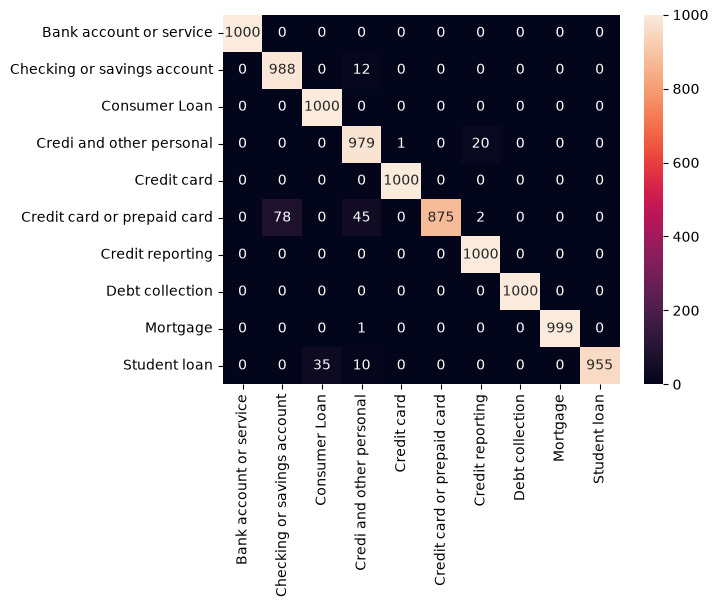

In [85]:
sns.heatmap(cm, annot=True, fmt='d', xticklabels=model.classes_, yticklabels=model.classes_)

in some cases 'Student loan' predicted as a 'Consumer loan'

In [86]:
mask = (y_test.to_numpy() != y_pred)
texts[mask].sample(20, random_state=42)

1093     unable to get your credit report or credit score
580                   problems when you are unable to pay
5836     unable to get your credit report or credit score
4312                 incorrect information on your report
3865                  problems when you are unable to pay
2920    problem with a credit reporting company's inve...
6561                                 closing your account
8044                  problems when you are unable to pay
9889     unable to get your credit report or credit score
9040                                 closing your account
4121                                 closing your account
8120                 incorrect information on your report
8265                  problems when you are unable to pay
7541                                 closing your account
3432                 incorrect information on your report
9471    problem with a credit reporting company's inve...
1299                  problems when you are unable to pay
4319     unabl